In [1]:
import hashlib
import os
import platform
import uuid
import sys

STUDENT_ID = 20244080202
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] pyhomework
[学号]       20244080202
[机器指纹] 0d25ba29a288e7c8
[RUN_ID]   20244080202-0d25ba29a288e7c8


In [2]:
#1
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def wigner_density(x):
    """返回半圆密度在 x 处的值（Python float）。"""
    x = float(x)
    if abs(x) > 2:
        return 0.0
    return float(np.sqrt(4 - x**2) / (2 * np.pi))


for value in (0, 1, 2, 2.5, np.float64(1.5), np.int64(0)):
    print(f"f({value:>4}) = {wigner_density(value):.6f}")

f(   0) = 0.318310
f(   1) = 0.275664
f(   2) = 0.000000
f( 2.5) = 0.000000
f( 1.5) = 0.210542
f(   0) = 0.318310


In [3]:
def generate_wigner(n):
    """生成 n×n 实对称 Wigner 矩阵，上三角元素服从 N(0, 1/n)。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    upper = np.triu(np.random.normal(0.0, 1.0 / np.sqrt(n), size=(n, n)))
    return upper + np.triu(upper, 1).T


def get_spectrum(matrix):
    """返回矩阵的全部特征值，按非递减顺序排列。"""
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix)))


demo = generate_wigner(5)
print("矩阵形状：", demo.shape)
print("是否对称：", np.allclose(demo, demo.T))
print("特征值：", np.round(get_spectrum(demo), 4))

for bad_n in (3.5, 0, -2):
    try:
        generate_wigner(bad_n)
    except (TypeError, ValueError) as exc:
        print(f"generate_wigner({bad_n!r}) -> {type(exc).__name__}: {exc}")

矩阵形状： (5, 5)
是否对称： True
特征值： [-2.2059  0.0285  0.2075  0.4265  1.5348]
generate_wigner(3.5) -> TypeError: n 必须是正整数
generate_wigner(0) -> ValueError: n 必须是正整数
generate_wigner(-2) -> ValueError: n 必须是正整数


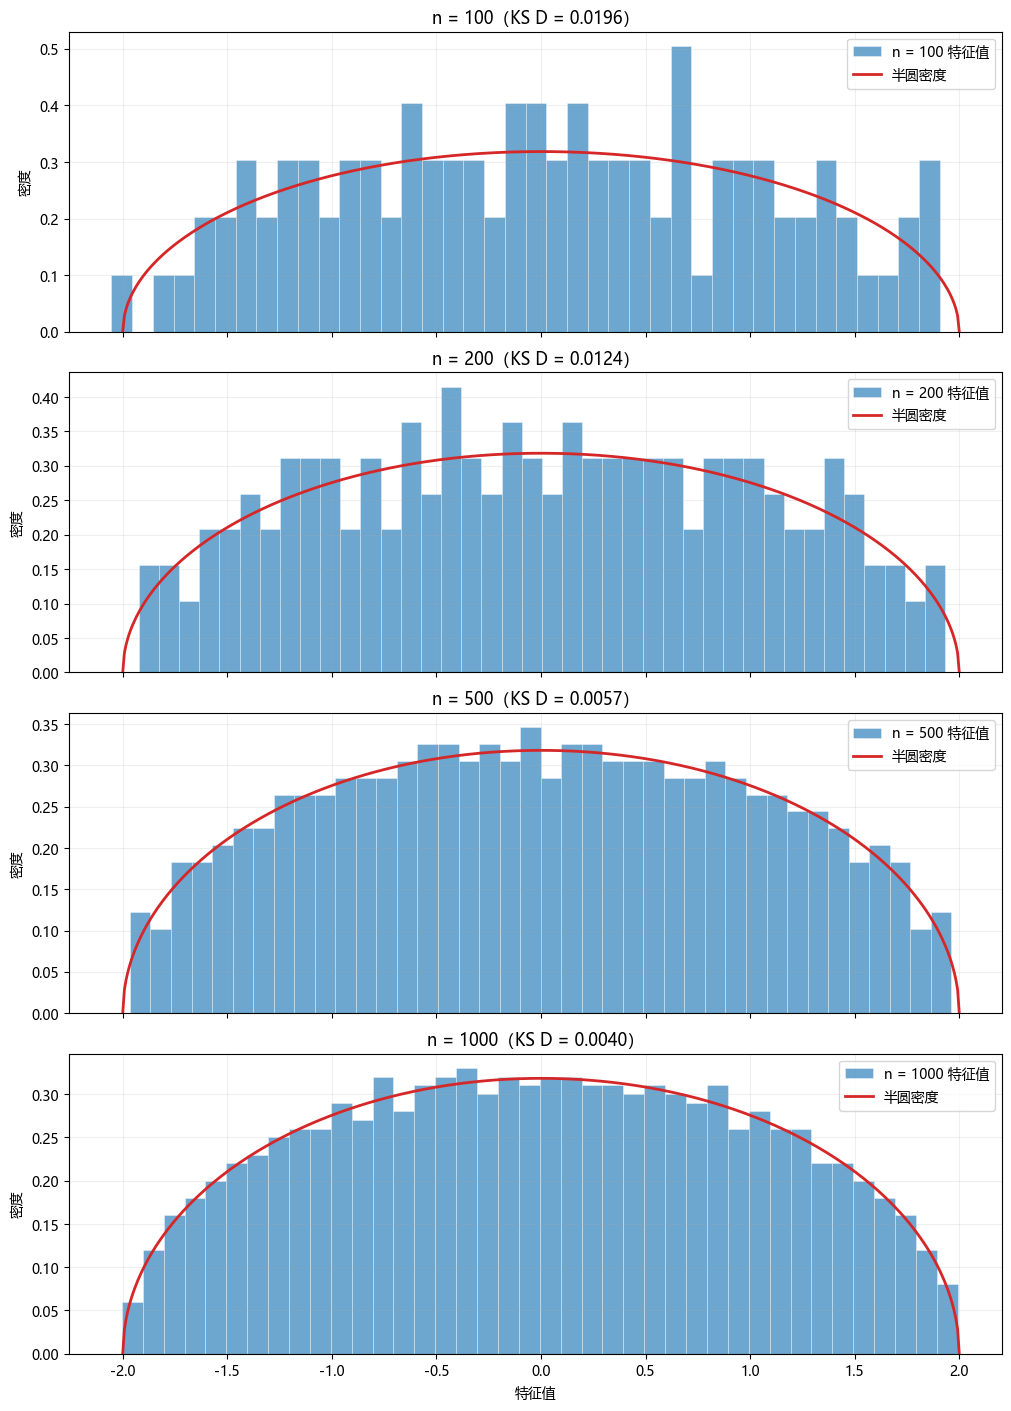

    n     KS D      p 值
  100   0.0196   1.0000
  200   0.0124   1.0000
  500   0.0057   1.0000
 1000   0.0040   1.0000


In [4]:
from scipy.stats import kstest


def wigner_cdf(x):
    """半圆密度的累积分布函数。"""
    x = np.asarray(x, dtype=float)
    middle = (0.5
              + x * np.sqrt(np.maximum(4 - x**2, 0.0)) / (4 * np.pi)
              + np.arcsin(np.clip(x / 2, -1, 1)) / np.pi)
    return np.where(x <= -2, 0.0, np.where(x >= 2, 1.0, middle))


np.random.seed(42)
ns = [100, 200, 500, 1000]
grid = np.linspace(-2, 2, 500)
density = np.sqrt(np.maximum(4 - grid**2, 0.0)) / (2 * np.pi)

fig, axes = plt.subplots(4, 1, figsize=(10, 14), sharex=True, constrained_layout=True)
ks_results = []

for ax, n in zip(axes, ns):
    eigenvalues = get_spectrum(generate_wigner(n))
    d_stat, p_value = kstest(eigenvalues, wigner_cdf)
    ks_results.append((n, d_stat, p_value))

    ax.hist(eigenvalues, bins=40, density=True, color="tab:blue",
            alpha=0.65, edgecolor="white", linewidth=0.4,
            label=f"n = {n} 特征值")
    ax.plot(grid, density, color="tab:red", linewidth=2, label="半圆密度")
    ax.set_title(f"n = {n}（KS D = {d_stat:.4f}）")
    ax.set_ylabel("密度")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("特征值")
plt.show()

print(f"{'n':>5} {'KS D':>8} {'p 值':>8}")
for n, d_stat, p_value in ks_results:
    print(f"{n:>5} {d_stat:>8.4f} {p_value:>8.4f}")

In [5]:
#2
def is_valid_board(board):
    """判断 board 是否为元素仅含 0/1 的二维 NumPy 数组。"""
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.isin(board, (0, 1)).all())


def gol_step(board):
    """按环绕边界规则演化一步，返回新的棋盘。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是元素仅为 0/1 的二维 NumPy 数组")

    neighbors = sum(
        np.roll(np.roll(board, dr, axis=0), dc, axis=1)
        for dr in (-1, 0, 1)
        for dc in (-1, 0, 1)
        if (dr, dc) != (0, 0)
    )
    alive = board == 1
    return ((alive & ((neighbors == 2) | (neighbors == 3)))
            | (~alive & (neighbors == 3))).astype(int)


samples = {
    "一维数组": np.array([0, 1]),
    "含非法值": np.array([[0, 2]]),
    "Python 列表": [[0, 1]],
}
for name, sample in samples.items():
    print(f"{name}：{is_valid_board(sample)}")

glider = np.zeros((6, 6), dtype=int)
glider[1, 2] = glider[2, 3] = glider[3, 1] = glider[3, 2] = glider[3, 3] = 1
print("\n初始棋盘：")
print(glider)
print("演化一步：")
print(gol_step(glider))

一维数组：False
含非法值：False
Python 列表：False

初始棋盘：
[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]
演化一步：
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 1 0 1 0 0]
 [0 0 1 1 0 0]
 [0 0 1 0 0 0]
 [0 0 0 0 0 0]]


初始状态：


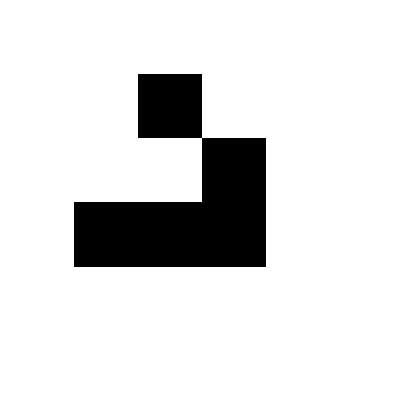

演化一步后：


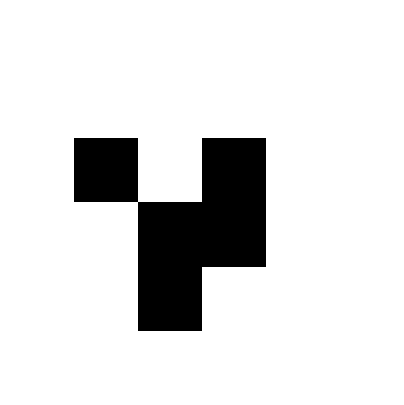

In [6]:
def draw_gol_board(board):
    """绘制棋盘：活细胞黑色，死细胞白色，不显示网格、刻度和坐标轴。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是元素仅为 0/1 的二维 NumPy 数组")

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(board, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_axis_off()
    plt.show()


print("初始状态：")
draw_gol_board(glider)
print("演化一步后：")
draw_gol_board(gol_step(glider))

In [7]:
#3
import pandas as pd
from pathlib import Path

iris_path = Path("iris.csv")
iris = pd.read_csv(iris_path)

iris = iris.drop(columns=["Id"])
iris = iris.rename(columns={
    "SepalLengthCm": "Sepal.Length",
    "SepalWidthCm": "Sepal.Width",
    "PetalLengthCm": "Petal.Length",
    "PetalWidthCm": "Petal.Width",
})
iris["Species"] = iris["Species"].str.replace("Iris-", "", regex=False)

print("数据点数量：", len(iris))
print("列名：", iris.columns.tolist())
print("各列数据类型：")
print(iris.dtypes)
print("花卉种类数：", iris["Species"].nunique())
print(iris["Species"].value_counts())
display(iris.head())

数据点数量： 150
列名： ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width', 'Species']
各列数据类型：
Sepal.Length    float64
Sepal.Width     float64
Petal.Length    float64
Petal.Width     float64
Species          object
dtype: object
花卉种类数： 3
Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [8]:
rows = [34, 37]
print("更正前：")
display(iris.loc[rows])

iris.loc[34, ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width", "Species"]] = [
    4.9, 3.1, 1.5, 0.2, "setosa"
]
iris.loc[37, ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width", "Species"]] = [
    4.9, 3.6, 1.4, 0.1, "setosa"
]

print("更正后：")
display(iris.loc[rows])

更正前：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.1,setosa
37,4.9,3.1,1.5,0.1,setosa


更正后：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa


In [9]:
iris["Petal.Ratio"] = iris["Petal.Length"] / iris["Petal.Width"]
iris["Sepal.Ratio"] = iris["Sepal.Length"] / iris["Sepal.Width"]

output_path = Path("iris_corrected.csv")
iris.to_csv(output_path, index=False, encoding="utf-8-sig")
print("已保存：", output_path.resolve())
print("DataFrame 形状：", iris.shape)
display(iris.head())

已保存： D:\python数据分析\iris_corrected.csv
DataFrame 形状： (150, 7)


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species,Petal.Ratio,Sepal.Ratio
0,5.1,3.5,1.4,0.2,setosa,7.0,1.457143
1,4.9,3.0,1.4,0.2,setosa,7.0,1.633333
2,4.7,3.2,1.3,0.2,setosa,6.5,1.468750
3,4.6,3.1,1.5,0.2,setosa,7.5,1.483871
4,5.0,3.6,1.4,0.2,setosa,7.0,1.388889


In [10]:
summary = (
    iris.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]]
    .agg(["mean", "median", "min", "max", "std"])
    .round(4)
)
display(summary)

Petal.Ratio                               Sepal.Ratio          \
                  mean  median     min   max     std        mean  median   
Species                                                                    
setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                    
               min     max     std  
Species                             
setosa      1.2683  1.9565  0.1187  
versicolor  1.7647  2.8182  0.2287  
virginica   1.8235  2.9615  0.2470